Importing plotly failed. Interactive plots will not work.


<Axes: xlabel='DATE'>

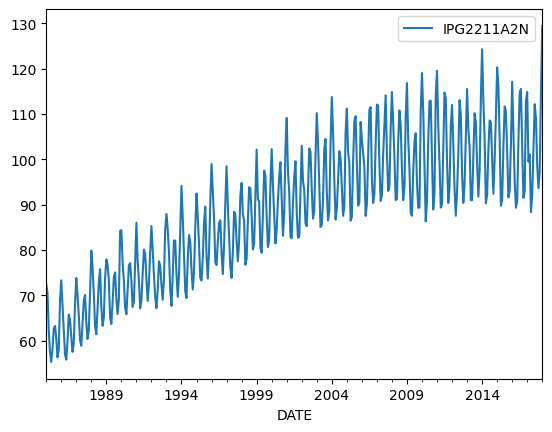

In [1]:
# No Google Colab o Prophet já vem instalado. Em outro ambiente, descomente a linha abaixo:
# !pip install prophet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)  # reduz mensagens de log

df=pd.read_csv("https://raw.githubusercontent.com/celsocrivelaro/simple-datasets/refs/heads/main/Electric_Production.csv")

df.set_index('DATE',inplace=True)
df.index=pd.to_datetime(df.index)
#drop null values
df.dropna(inplace=True)
df.plot()

### 1. Médias móveis

Faça a análise pelo modelo de Médias Móveis:
- Por ano
- Por mês

Qual seria a previsão de consumo para início de 2020?

Dica: use `df.rolling(N).mean()` e `df.rolling(N).std()`, escolhendo a janela $N$ adequada.

In [2]:
# Médias móveis




*Previsão para início de 2020 pela média móvel:*

### 2. Aplicar o Prophet

Prepare os dados no formato do Prophet (colunas `ds` e `y`):

```python
df_prophet = df.reset_index().rename(columns={'DATE': 'ds', 'IPG2211A2N': 'y'})
```

a) Separe os **últimos 24 meses** para teste e o restante para treino.

b) Escolha o modo da sazonalidade (`'additive'` ou `'multiplicative'`) olhando o gráfico e o desvio padrão móvel. Lembre que os dados são mensais: `weekly_seasonality=False` e `daily_seasonality=False`.

c) Treine o modelo, faça a previsão para o período de teste e calcule o **RMSE**. Compare com um baseline simples (por exemplo, a média móvel de 12 meses do final do treino).

d) Plote a previsão (`modelo.plot`) e os componentes (`modelo.plot_components`). Interprete a tendência e a sazonalidade.

e) Treine novamente com **todos** os dados e responda: qual seria a previsão de consumo para início de 2020 (2020-01)? Compare com a previsão da média móvel.

Dica: a série termina em 2018-01. Use `modelo.make_future_dataframe(periods=..., freq='MS')`.

In [3]:
# a) Treino e teste




In [4]:
# b) e c) Modelo, previsão no teste e RMSE




In [5]:
# d) Gráficos




In [6]:
# e) Previsão para 2020-01




*Interpretação e comparação:*